In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
rng = np.random.default_rng(42)

In [3]:
from sklearn.datasets import fetch_california_housing
data = fetch_california_housing ()
X , y = data.data , data.target

### Problem 1: Simple Linear Regression from Scratch 

**(a) Dataset B**

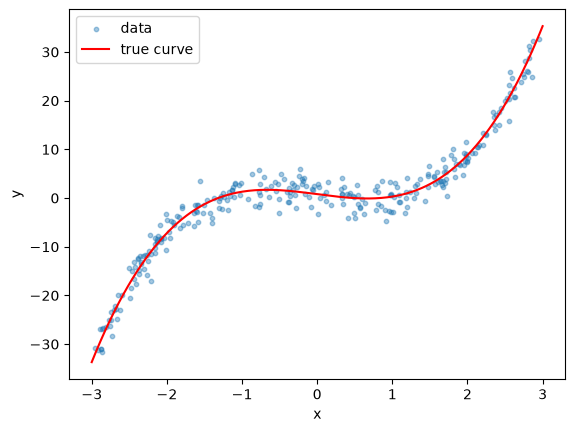

In [ ]:
N = 300
x = rng.uniform(-3, 3, N)
y = 1.5*x**3 - 2*x + 0.8 + rng.normal(0, 2, N)

idx = rng.permutation(N)
train_idx, test_idx = idx[:240], idx[240:]
x_tr, y_tr = x[train_idx], y[train_idx]
x_te, y_te = x[test_idx], y[test_idx]

x_grid = np.linspace(-3, 3, 300)
plt.scatter(x, y, s=10, alpha=0.4, label="data")
plt.plot(x_grid, 1.5*x_grid**3 - 2*x_grid + 0.8, 'r-', label="true curve")
plt.xlabel("x"); plt.ylabel("y"); plt.legend()

**(b) Closed-form OLS solution**

In [11]:
def fit_ols(X, y):
    return np.linalg.inv(X.T @ X) @ X.T @ y

def poly_features(x, D):
    return np.column_stack([x**k for k in range(D+1)])

X_tr1 = poly_features(x_tr, 1)
theta_manual = fit_ols(X_tr1, y_tr)

# Check 1 -- do the normal equations actually hold at this solution?
lhs = X_tr1.T @ X_tr1 @ theta_manual
rhs = X_tr1.T @ y_tr
print("max abs residual in X^T X theta - X^T y:", np.max(np.abs(lhs - rhs)))

# Check 2 -- does an independent NumPy solver agree?
theta_lstsq, *_ = np.linalg.lstsq(X_tr1, y_tr, rcond=None)
print("manual theta:", theta_manual)
print("lstsq theta: ", theta_lstsq)
print("max abs diff:", np.max(np.abs(theta_manual - theta_lstsq)))

max abs residual in X^T X theta - X^T y: 1.8189894035458565e-12
manual theta: [0.47302996 5.78103395]
lstsq theta:  [0.47302996 5.78103395]
max abs diff: 1.7763568394002505e-15


**(c) Fitting simple linear model**

In [14]:
X_tr1 = poly_features(x_tr, 1)
X_te1 = poly_features(x_te, 1)
theta1 = fit_ols(X_tr1, y_tr)
mse_tr1 = np.mean((y_tr - X_tr1@theta1)**2)
mse_te1 = np.mean((y_te - X_te1@theta1)**2)

print(f"Theta     = {theta1}")
print(f"Train MSE = {mse_tr1}")
print(f"Test MSE  = {mse_te1}")

Theta     = [0.47302996 5.78103395]
Train MSE = 35.03615211501976
Test MSE  = 44.44744656854039


**(d) Residuals vs. fitted values**

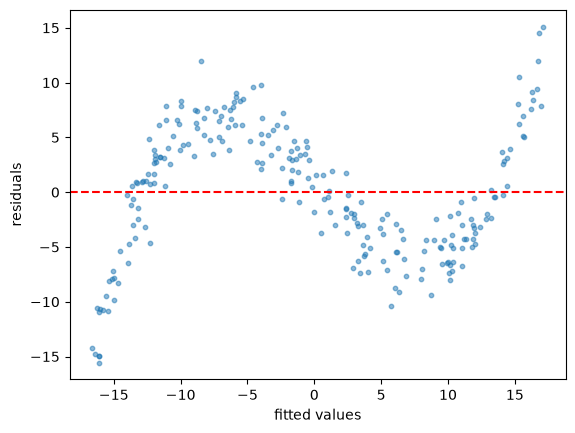

In [15]:
residuals = y_tr - X_tr1@theta1
fitted = X_tr1@theta1
plt.scatter(fitted, residuals, s=10, alpha=0.5)
plt.axhline(0, color='r', linestyle='--')
plt.xlabel("fitted values"); plt.ylabel("residuals")
plt.show()

### Linear Models with Polynomial Features

**(a) - (b) Fitting each degree**

D |      Train MSE       |       Test MSE      
1 | 35.03615211501976    | 44.44744656854039   
2 | 34.426406296852164   | 47.643950815583835  
3 | 3.966368342753691    | 4.543022660522873   
4 | 3.9399503660127846   | 4.734528709965037   
6 | 3.9362088641188455   | 4.679552322142708   
9 | 3.907600734996109    | 4.540349195702239   


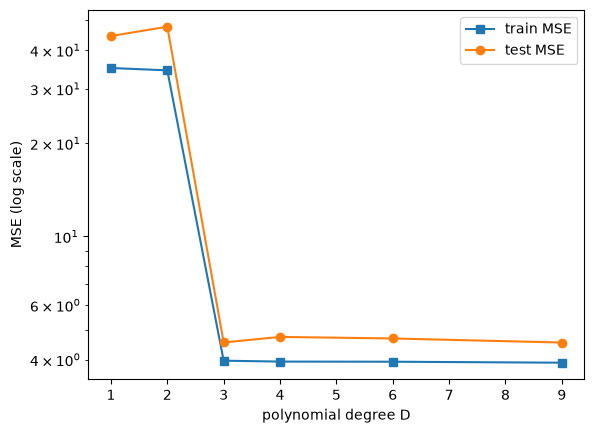

In [20]:
degrees = [1,2,3,4,6,9]
results = {}

print(f"{'D':<1} | {'Train MSE':^20} | {'Test MSE':^20}")
for D in degrees:
    Xtr = poly_features(x_tr, D)
    Xte = poly_features(x_te, D)
    theta = fit_ols(Xtr, y_tr)
    mse_tr = np.mean((y_tr - Xtr@theta)**2)
    mse_te = np.mean((y_te - Xte@theta)**2)
    results[D] = (theta, mse_tr, mse_te)
    print(f"{D:<1} | {mse_tr:<20} | {mse_te:<20}")

plt.semilogy(degrees, [results[d][1] for d in degrees], 's-', label="train MSE")
plt.semilogy(degrees, [results[d][2] for d in degrees], 'o-', label="test MSE")
plt.xlabel("polynomial degree D"); plt.ylabel("MSE (log scale)")
plt.legend() 
plt.show()

**(c) Coefficients at D = 3**

In [27]:
estimated = results[3]
true = [0.8, -2, 0, 1.5]

print(f"Estimated: {estimated[0]}")
print(f"True:      {true}")


Estimated: [ 0.76694721 -1.8752372   0.00869506  1.47516902]
True:      [0.8, -2, 0, 1.5]


**(d) Plotting D**

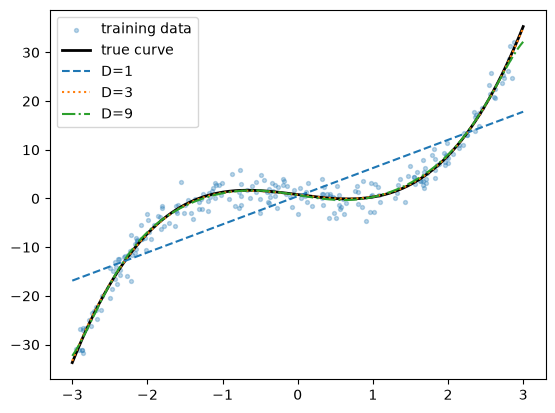

In [28]:
x_grid = np.linspace(-3,3,300)
plt.scatter(x_tr, y_tr, s=8, alpha=0.3, label="training data")
plt.plot(x_grid, 1.5*x_grid**3-2*x_grid+0.8, 'k-', linewidth=2, label="true curve")
for D, style in zip([1,3,9], ['--',':','-.']):
    theta = results[D][0]
    Xg = poly_features(x_grid, D)
    plt.plot(x_grid, Xg@theta, style, label=f"D={D}")
plt.legend()
plt.show()